In [1]:
import pandas as pd           # data cleaning, preporcessing, transformation
import numpy as np            # numerical calculations, linear algebra
import matplotlib.pyplot as plt  # visualization
import seaborn as sns 

In [2]:
sp = pd.read_csv('sp.csv')
orders = pd.read_csv('orders.csv')
cs = pd.read_csv('cust_sub.csv')
cb = pd.read_csv('cust_bio.csv')
ca = pd.read_csv('cust_activity.csv')

In [3]:
import warnings
warnings.filterwarnings('ignore')

In [4]:
print(ca.shape)
print(cb.shape)
print(cs.shape)
print(orders.shape)
print(sp.shape)

(7500, 3)
(478, 3)
(51, 3)
(127, 4)
(6, 5)


In [5]:
print(ca.columns)
print(cb.columns)
print(cs.columns)
print(orders.columns)
print(sp.shape)

Index(['Cust_ID', 'Activity', 'Date'], dtype='str')
Index(['Cust_ID', 'City', 'Age'], dtype='str')
Index(['Cust_ID', 'Plan_Var_ID', 'Purchase_Date'], dtype='str')
Index(['Order_id', 'Cust_ID', 'Amount', 'Payment_mode'], dtype='str')
(6, 5)


#### 1) Check null values and duplicates in each df.

In [6]:
for i in [ca,cb,cs,orders,sp]:
    print(i.isnull().sum())

Cust_ID     0
Activity    0
Date        0
dtype: int64
Cust_ID    0
City       0
Age        0
dtype: int64
Cust_ID          0
Plan_Var_ID      0
Purchase_Date    0
dtype: int64
Order_id        0
Cust_ID         0
Amount          0
Payment_mode    0
dtype: int64
Plan_Var_ID    0
Plan_ID        0
Plan_name      0
Price          0
Duration       0
dtype: int64


In [7]:
def check_dup(data):
    dup = data.duplicated().sum()
    if dup > 0:
        print(dup)
    else:
        print('No Duplicates')

In [8]:
for i in [ca,cb,cs,orders,sp]:
    check_dup(i)

No Duplicates
No Duplicates
No Duplicates
No Duplicates
No Duplicates


In [9]:
import plotly.express as px

#### 2) Find Count of Customers from each city and represent it on bar chart.

In [10]:
q2 = cb['City'].value_counts().reset_index()
q2

,City,count
0,Chennai,109
1,Delhi,106
2,Kolkata,94
3,Noida,92
4,Mumbai,77


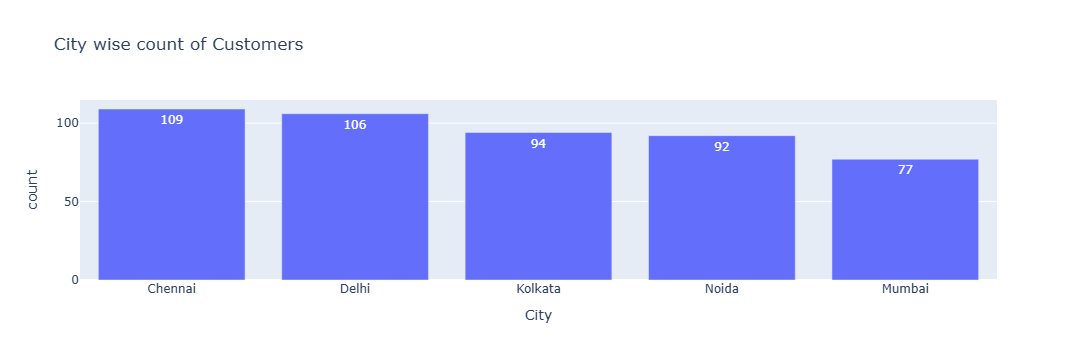

In [11]:
fig = px.bar(data_frame = q2, x = 'City', y = 'count', title='City wise count of Customers',
             text='count')
fig.show()

#### 3) Find Range Age wise count of cutsomers, represent it on pie chart.

In [12]:
cb['Age'].describe()

count    478.000000
mean      28.740586
std        5.376756
min       20.000000
25%       24.000000
50%       29.000000
75%       34.000000
max       37.000000
Name: Age, dtype: float64

In [13]:
cb['Age_Range'] = pd.cut(cb['Age'], bins = [19,24,29,34,39])
cb['Age_Range'] = cb['Age_Range'].astype(str)

In [14]:
q3 = cb['Age_Range'].value_counts().reset_index()
q3

,Age_Range,count
0,"(19, 24]",137
1,"(29, 34]",130
2,"(24, 29]",120
3,"(34, 39]",91


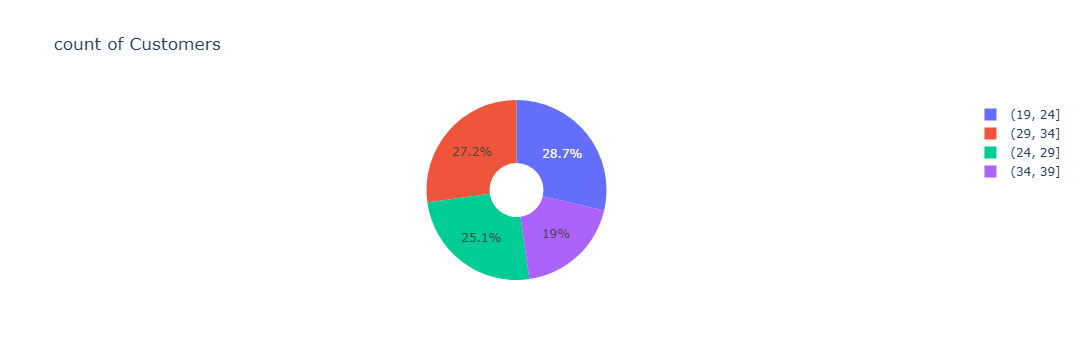

In [15]:
fig = px.pie(data_frame = q3, names = 'Age_Range', values = 'count', title='count of Customers',hole=0.3)
fig.show()

#### 4) Find Count of each activity, represent it on bar chart

In [16]:
q4 = ca['Activity'].value_counts().reset_index()
q4

,Activity,count
0,Browse,6548
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


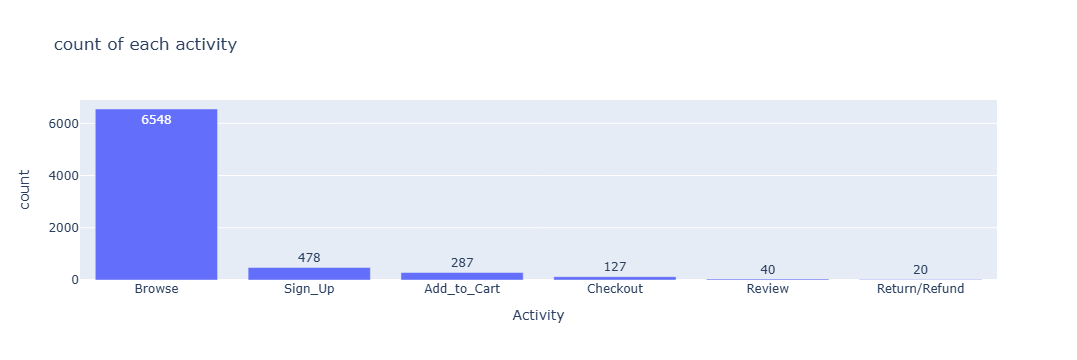

In [17]:
fig = px.bar(data_frame = q4, x = 'Activity', y = 'count', title='count of each activity',text='count')      # text is used to display data labels
fig.show()

#### 5) Find order month wise total amount. Represent it on line chart.

In [18]:
print(ca.columns)
print(orders.columns)

Index(['Cust_ID', 'Activity', 'Date'], dtype='str')
Index(['Order_id', 'Cust_ID', 'Amount', 'Payment_mode'], dtype='str')


In [19]:
cs.head()

,Cust_ID,Plan_Var_ID,Purchase_Date
0,CUS_626,P1_1Y,2025-05-15
1,CUS_723,P1_1Y,2024-07-23
2,CUS_575,P1_1Y,2024-11-14
3,CUS_232,P2_6M,2025-04-19
4,CUS_346,P2_1Y,2024-01-31


In [20]:
cs.dtypes

Cust_ID          str
Plan_Var_ID      str
Purchase_Date    str
dtype: object

In [21]:
print(ca.shape)
print(orders.shape)

(7500, 3)
(127, 4)


In [22]:
ca.dtypes

Cust_ID     str
Activity    str
Date        str
dtype: object

In [23]:
ca['Date'] = pd.to_datetime(ca['Date'])
ca['Month'] = ca['Date'].dt.month

In [24]:
ca_checkout = ca[ca['Activity']=='Checkout']
print(ca_checkout.shape)
print(orders.shape)

(127, 4)
(127, 4)


In [25]:
ca_orders = pd.merge(orders, ca_checkout, on='Cust_ID',how='inner')
ca_orders.head()

,Order_id,Cust_ID,Amount,Payment_mode,Activity,Date,Month
0,ORD_71,CUS_545,2123.19,UPI,Checkout,2024-04-26,4
1,ORD_72,CUS_622,2788.02,Net Banking,Checkout,2024-02-01,2
2,ORD_73,CUS_418,3071.63,Credit_Card,Checkout,2024-07-22,7
3,ORD_74,CUS_360,5736.31,COD,Checkout,2025-05-24,5
4,ORD_75,CUS_714,1592.53,Debit Card,Checkout,2024-06-19,6


In [26]:
q5 = ca_orders.groupby('Month')['Amount'].sum().reset_index()
q5

,Month,Amount
0,1,27022.20
1,2,70477.42
2,3,74777.59
3,4,88080.66
4,5,60200.46
5,6,69580.07
6,7,80416.05
7,8,27227.29
8,9,34804.62
9,10,30298.38


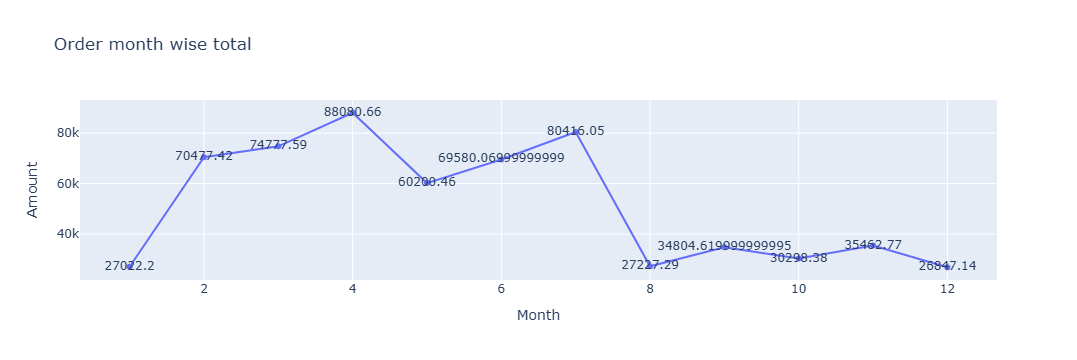

In [27]:
fig = px.line(data_frame = q5, x='Month', y='Amount', title='Order month wise total',text='Amount')
fig.show()

#### 6) Find Sub_Plan wise total revenue generated. Represent it on bar chart.

In [28]:
print(sp.columns)
print(cs.columns)

Index(['Plan_Var_ID', 'Plan_ID', 'Plan_name', 'Price', 'Duration'], dtype='str')
Index(['Cust_ID', 'Plan_Var_ID', 'Purchase_Date'], dtype='str')


In [29]:
print(sp.shape)
print(cs.shape)

(6, 5)
(51, 3)


In [30]:
cs.head()

,Cust_ID,Plan_Var_ID,Purchase_Date
0,CUS_626,P1_1Y,2025-05-15
1,CUS_723,P1_1Y,2024-07-23
2,CUS_575,P1_1Y,2024-11-14
3,CUS_232,P2_6M,2025-04-19
4,CUS_346,P2_1Y,2024-01-31


In [31]:
cs_sp = pd.merge(cs,sp,on='Plan_Var_ID', how='inner')
cs_sp.head()

,Cust_ID,Plan_Var_ID,Purchase_Date,Plan_ID,Plan_name,Price,Duration
0,CUS_626,P1_1Y,2025-05-15,P1,Silver,1200.0,1 Year
1,CUS_723,P1_1Y,2024-07-23,P1,Silver,1200.0,1 Year
2,CUS_575,P1_1Y,2024-11-14,P1,Silver,1200.0,1 Year
3,CUS_232,P2_6M,2025-04-19,P2,Gold,1440.0,6 Months
4,CUS_346,P2_1Y,2024-01-31,P2,Gold,2400.0,1 Year


In [32]:
q6 = cs_sp.groupby('Plan_Var_ID')['Price'].sum().reset_index()
q6

,Plan_Var_ID,Price
0,P1_1Y,16800.0
1,P1_6M,5040.0
2,P2_1Y,24000.0
3,P2_6M,7200.0
4,P3_1Y,28800.0
5,P3_6M,25920.0


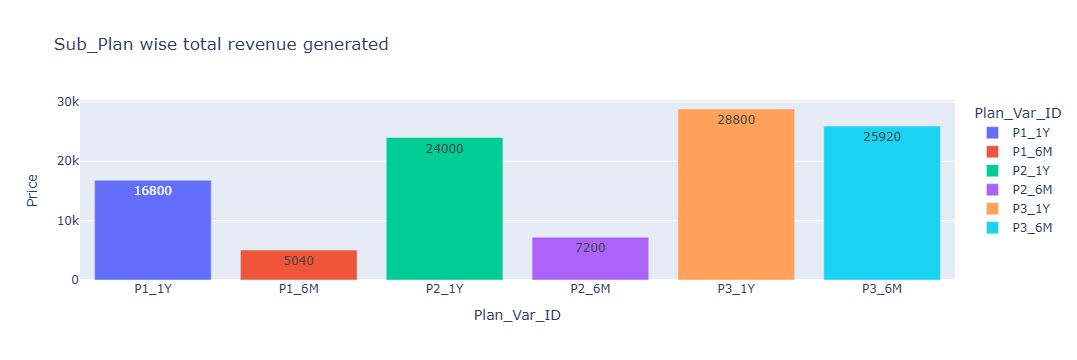

In [33]:
fig = px.bar(data_frame = q6, x = 'Plan_Var_ID', y = 'Price', title='Sub_Plan wise total revenue generated',text='Price',
            color='Plan_Var_ID')      # text is used to display data labels
fig.show()

#### 7) City wise find total amount

In [34]:
print(cb.columns)
print(orders.columns)

Index(['Cust_ID', 'City', 'Age', 'Age_Range'], dtype='str')
Index(['Order_id', 'Cust_ID', 'Amount', 'Payment_mode'], dtype='str')


In [35]:
cb_orders= pd.merge(cb,orders,on='Cust_ID',how='inner')
cb_orders.head()

,Cust_ID,City,Age,Age_Range,Order_id,Amount,Payment_mode
0,CUS_121,Noida,30,"(29, 34]",ORD_83,3336.69,UPI
1,CUS_127,Delhi,24,"(19, 24]",ORD_172,6427.90,Credit_Card
2,CUS_129,Mumbai,20,"(19, 24]",ORD_97,8653.62,UPI
3,CUS_135,Kolkata,35,"(34, 39]",ORD_87,2551.37,Credit_Card
4,CUS_139,Noida,34,"(29, 34]",ORD_127,3290.14,UPI


In [36]:
q7 = cb_orders.groupby('City')['Amount'].sum().reset_index()
q7

,City,Amount
0,Chennai,96763.72
1,Delhi,147176.17
2,Kolkata,102185.83
3,Mumbai,120515.98
4,Noida,158552.95


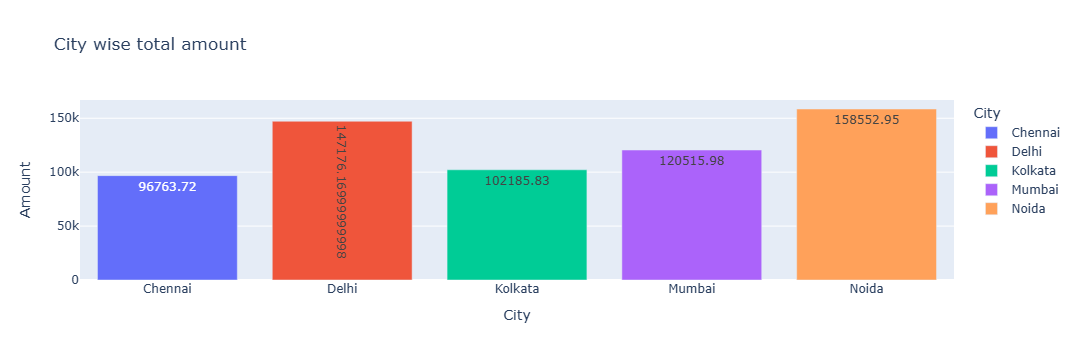

In [37]:
fig = px.bar(data_frame = q7, x = 'City', y = 'Amount', title='City wise total amount',text='Amount',color='City')      
fig.show()

#### Funnel Analysis

#### 1) Generate the entire funnel. represent 
Funnel_Stage, Count_of_Cust, Percentage_Conversion

In [38]:
ca.head()

,Cust_ID,Activity,Date,Month
0,CUS_121,Sign_Up,2024-04-24,4
1,CUS_121,Browse,2024-04-27,4
2,CUS_121,Add_to_Cart,2024-04-27,4
3,CUS_121,Browse,2024-04-29,4
4,CUS_121,Browse,2024-04-30,4


In [39]:
ca['Activity'].value_counts()

Activity
Browse           6548
Sign_Up           478
Add_to_Cart       287
Checkout          127
Review             40
Return/Refund      20
Name: count, dtype: int64

In [40]:
w1 = ca.groupby(['Cust_ID','Activity'])['Activity'].count().reset_index(name='Count')
w1.head()

,Cust_ID,Activity,Count
0,CUS_121,Add_to_Cart,1
1,CUS_121,Browse,8
2,CUS_121,Checkout,1
3,CUS_121,Sign_Up,1
4,CUS_122,Browse,10


In [41]:
funnel = w1['Activity'].value_counts().reset_index()
funnel

,Activity,count
0,Browse,681
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


In [42]:
funnel['Prev_Count'] = np.where(funnel['Activity']=='Return/Refund',
                                funnel['count'].shift(2),
                                funnel['count'].shift(1))
funnel

,Activity,count,Prev_Count
0,Browse,681,NaN
1,Sign_Up,478,681.0
2,Add_to_Cart,287,478.0
3,Checkout,127,287.0
4,Review,40,127.0
5,Return/Refund,20,127.0


In [43]:
funnel['Per_Conversion'] = round((funnel['count']/funnel['Prev_Count'])*100,2)
funnel.fillna(0,inplace=True)
funnel

,Activity,count,Prev_Count,Per_Conversion
0,Browse,681,0.0,0.00
1,Sign_Up,478,681.0,70.19
2,Add_to_Cart,287,478.0,60.04
3,Checkout,127,287.0,44.25
4,Review,40,127.0,31.50
5,Return/Refund,20,127.0,15.75


In [44]:
funnel['Per_Conversion'] = funnel['Per_Conversion'].apply(lambda x : str(x) + '%')
funnel

,Activity,count,Prev_Count,Per_Conversion
0,Browse,681,0.0,0.0%
1,Sign_Up,478,681.0,70.19%
2,Add_to_Cart,287,478.0,60.04%
3,Checkout,127,287.0,44.25%
4,Review,40,127.0,31.5%
5,Return/Refund,20,127.0,15.75%


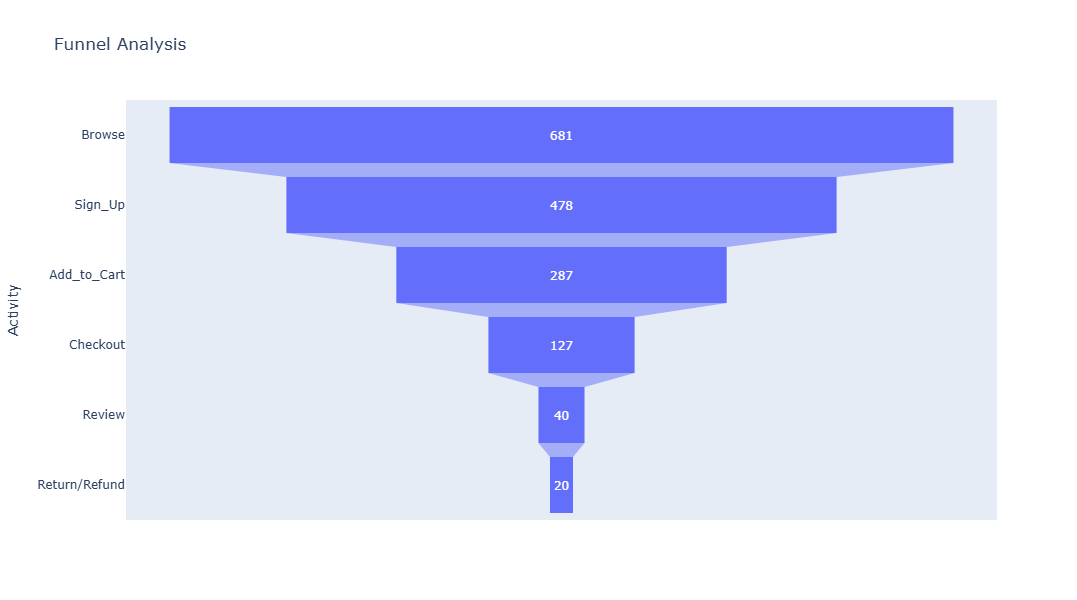

In [45]:
fig = px.funnel(data_frame=funnel,y='Activity',x='count',title='Funnel Analysis',height=600,hover_data='Per_Conversion')
fig.show()

#### 2) Find Customer wise count of days to transition from one stage of funnel to the next stage


In [46]:
ca.head(20)

,Cust_ID,Activity,Date,Month
0,CUS_121,Sign_Up,2024-04-24,4
1,CUS_121,Browse,2024-04-27,4
2,CUS_121,Add_to_Cart,2024-04-27,4
3,CUS_121,Browse,2024-04-29,4
4,CUS_121,Browse,2024-04-30,4
5,CUS_121,Browse,2024-05-04,5
6,CUS_121,Checkout,2024-05-05,5
7,CUS_121,Browse,2024-05-07,5
8,CUS_121,Browse,2024-05-09,5
9,CUS_121,Browse,2024-05-10,5


In [47]:
pt1 = pd.pivot_table(data=ca,index=['Cust_ID'],columns=['Activity'],
                     values='Date', aggfunc='min')
pt1.head(15)

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up
Cust_ID,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15
CUS_126,NaT,2024-02-28,NaT,NaT,NaT,2024-02-27
CUS_127,2024-05-28,2024-05-28,2024-06-16,NaT,NaT,2024-05-26
CUS_128,NaT,2024-06-12,NaT,NaT,NaT,NaT
CUS_129,2025-03-22,2025-03-22,2025-04-02,NaT,NaT,2025-03-21


In [48]:
# DD = DateDiff
pt1['DD_Browse_2_Signup'] = abs((pt1['Sign_Up'] - pt1['Browse']).dt.days)
pt1['DD_Signup_2_Add2Cart'] = (pt1['Add_to_Cart'] - pt1['Sign_Up']).dt.days
pt1['DD_Add2Cart_2_Checkout'] = (pt1['Checkout'] - pt1['Add_to_Cart']).dt.days
pt1['DD_Checkout_2_Review'] = (pt1['Review'] - pt1['Checkout']).dt.days
pt1['DD_Checkout_2_Return/Refund'] = (pt1['Return/Refund'] - pt1['Checkout']).dt.days
pt1.head()

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up,DD_Browse_2_Signup,DD_Signup_2_Add2Cart,DD_Add2Cart_2_Checkout,DD_Checkout_2_Review,DD_Checkout_2_Return/Refund
Cust_ID,,,,,,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24,3.0,3.0,8.0,NaN,NaN
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05,1.0,1.0,NaN,NaN,NaN
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15,2.0,NaN,NaN,NaN,NaN


In [49]:
pt2 = pt1.iloc[:,-5:] # all rowns and last 5 columns
pt2.head(2)

Activity,DD_Browse_2_Signup,DD_Signup_2_Add2Cart,DD_Add2Cart_2_Checkout,DD_Checkout_2_Review,DD_Checkout_2_Return/Refund
Cust_ID,,,,,
CUS_121,3.0,3.0,8.0,NaN,NaN
CUS_122,NaN,NaN,NaN,NaN,NaN


In [51]:
tran_days = pt2.mean()
tran_days

Activity
DD_Browse_2_Signup              2.516736
DD_Signup_2_Add2Cart            2.512195
DD_Add2Cart_2_Checkout         14.425197
DD_Checkout_2_Review            2.625000
DD_Checkout_2_Return/Refund     3.400000
dtype: float64

In [56]:
avg_days_to_tran = [0] + list(tran_days.values)
print(avg_days_to_tran)

[0, np.float64(2.51673640167364), np.float64(2.5121951219512195), np.float64(14.4251968503937), np.float64(2.625), np.float64(3.4)]


In [52]:
funnel

,Activity,count,Prev_Count,Per_Conversion
0,Browse,681,0.0,0.0%
1,Sign_Up,478,681.0,70.19%
2,Add_to_Cart,287,478.0,60.04%
3,Checkout,127,287.0,44.25%
4,Review,40,127.0,31.5%
5,Return/Refund,20,127.0,15.75%


In [57]:
funnel['Avg_Days_2Tran'] = avg_days_to_tran
funnel['Avg_Days_2Tran'] = funnel['Avg_Days_2Tran'].apply(lambda x : round(x,2))
funnel

,Activity,count,Prev_Count,Per_Conversion,Avg_Days_2Tran
0,Browse,681,0.0,0.0%,0.00
1,Sign_Up,478,681.0,70.19%,2.52
2,Add_to_Cart,287,478.0,60.04%,2.51
3,Checkout,127,287.0,44.25%,14.43
4,Review,40,127.0,31.5%,2.62
5,Return/Refund,20,127.0,15.75%,3.40


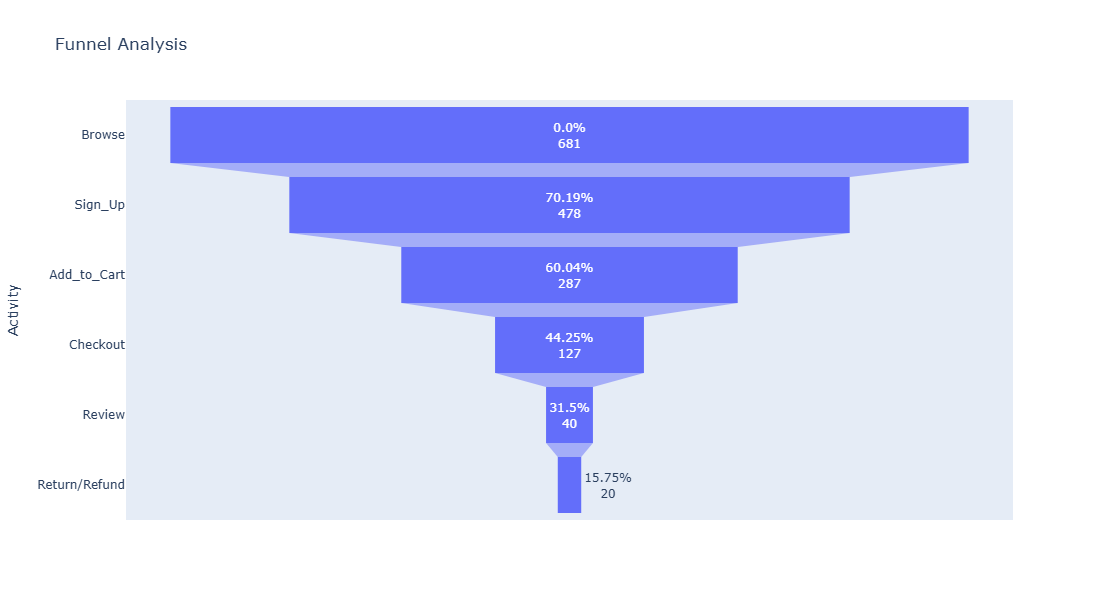

In [59]:
fig = px.funnel(data_frame = funnel, y='Activity', x='count',text='Per_Conversion',
                title='Funnel Analysis', height=600, hover_data='Avg_Days_2Tran')
fig.show()

#### city wise funnel

In [61]:
def city_wise_funnel(city_name):
    city_df = cb[cb['city']==city_name]

#### window function in pandas

1) lead,lag,- shift
2) rank, dense_rank, row_number - rank

In [64]:
demo = pd.DataFrame({'City':['Delhi']*5 + ['Noida']*5 + ['Pune']*5,
                     'Sales' : [5000,6000,6000,7500,9000,3500,4200,5400,8700,8700,11500,14500,
                                18000,18000,18000],
                     'Year' : [2015,2016,2017,2018,2019]*3})
#demo

In [63]:
demo1 = demo.copy()

In [65]:
noida = demo.query("City=='Noida'")
noida

,City,Sales,Year
5,Noida,3500,2015
6,Noida,4200,2016
7,Noida,5400,2017
8,Noida,8700,2018
9,Noida,8700,2019


In [66]:
noida['Rank_min'] = noida['Sales'].rank(ascending=False,method='min')
noida['Rank_max'] = noida['Sales'].rank(ascending=False,method='max')
noida['Rank_avg'] = noida['Sales'].rank(ascending=False,method='average')
noida['Rank_first'] = noida['Sales'].rank(ascending=False,method='first')
noida['Rank_dense'] = noida['Sales'].rank(ascending=False,method='dense')
noida

,City,Sales,Year,Rank_min,Rank_max,Rank_avg,Rank_first,Rank_dense
5,Noida,3500,2015,5.0,5.0,5.0,5.0,4.0
6,Noida,4200,2016,4.0,4.0,4.0,4.0,3.0
7,Noida,5400,2017,3.0,3.0,3.0,3.0,2.0
8,Noida,8700,2018,1.0,2.0,1.5,1.0,1.0
9,Noida,8700,2019,1.0,2.0,1.5,2.0,1.0


#### find city wise top 3 sales ? -use demo1

In [ ]:
# select * from
#(select city,sales, row_numbaer() over (partition by city order by sales desc)RN
# from demo1) dt where RN<=3;

In [68]:
demo2 = demo1.copy()

In [70]:
demo1['Rank'] = demo1.groupby('City')['Sales'].rank(ascending=False,method='dense')
demo1

,City,Sales,Year,Rank
0,Delhi,5000,2015,4.0
1,Delhi,6000,2016,3.0
2,Delhi,6000,2017,3.0
3,Delhi,7500,2018,2.0
4,Delhi,9000,2019,1.0
5,Noida,3500,2015,4.0
6,Noida,4200,2016,3.0
7,Noida,5400,2017,2.0
8,Noida,8700,2018,1.0
9,Noida,8700,2019,1.0


In [71]:
top3 = demo1[demo1['Rank']<=3]
top3

,City,Sales,Year,Rank
1,Delhi,6000,2016,3.0
2,Delhi,6000,2017,3.0
3,Delhi,7500,2018,2.0
4,Delhi,9000,2019,1.0
6,Noida,4200,2016,3.0
7,Noida,5400,2017,2.0
8,Noida,8700,2018,1.0
9,Noida,8700,2019,1.0
10,Pune,11500,2015,3.0
11,Pune,14500,2016,2.0


#### Q) Find city and sales where sales is more than avg salaes for that city

In [74]:
# demo2.head()

#select d2.city, d2.sales from demo2 d2 where d2.sales > 
#(select avg(d1.sales) from demo 2 d1 where d1.city = d2.city);

In [76]:
w1 = demo2.groupby('City')['Sales'].mean().reset_index()
w1.columns = ['City','Avg_Sales']
w1

,City,Avg_Sales
0,Delhi,6700.0
1,Noida,6100.0
2,Pune,16000.0


In [78]:
w2 = pd.merge(demo2,w1,on='City')
res = w2[w2['Sales']> w2['Avg_Sales']]
res

,City,Sales,Year,Avg_Sales
3,Delhi,7500,2018,6700.0
4,Delhi,9000,2019,6700.0
8,Noida,8700,2018,6100.0
9,Noida,8700,2019,6100.0
12,Pune,18000,2017,16000.0
13,Pune,18000,2018,16000.0
14,Pune,18000,2019,16000.0


In [ ]:
# github - version control
# repository - storage unit